# (optionnel) Personnalisation et production de graphiques avec Matplotlib

Dans cet exercice, on travaille sur les [données en accès libre de la Métropole de Grenoble]((https://data.metropolegrenoble.fr/visualisation/information/?id=resultats_de_l_observatoire_des_comptages_de_mobilite&resource_id=27321663-a35d-4588-a417-71c429cd8c7f)) concernant les **comptages de cyclistes sur les différents axes de la ville**.

Le but est d'essayer de reproduire certains graphiques visibles sur [cette page](https://data.metropolegrenoble.fr/Tableau-de-bord-velo-grenoble?).

👉 Allez la visiter pour voir ce qu'il est possible de faire en Data Visualisation à partir d'un DataFrame pandas.

*NB: depuis la publication de ces données, le SMMAG a réalisé un [tableau de bord](https://smmag.eco-counter.com/) encore plus complet et mis à jour régulièrement sur la fréquentation des axes par les cyclistes, piétons et trotinettes.*

## Importer les données

👉 Exécutez la cellule suivante pour configurer le notebook et charger les données.

In [ ]:
# Run this cell to configure the notebook
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

bike = pd.read_csv("data_velo_grenoble.csv", delimiter=',', decimal='.')
bike.head()

Les colonnes sont les suivantes :

- `id` et `nom_post` désignent l'axe routier où est installé le compteur à vélpo
- `nom_comm` désigne la commune
- `annee` correspond à l'année de la mesure
- `tmj` désigne le nombre de passages moyen par jour
- `tmjo` désigne le nombre de passages moyen par jour en semaine
- `tmjwe` désigne le nombre de passages moyen par jour le week-end

## Personnaliser un graphique

On essaye dans cette partie de reproduire ce graphique sur le comptage de vélos en 2022 (ou du moins de s'en rapprocher le plus possible !) : 

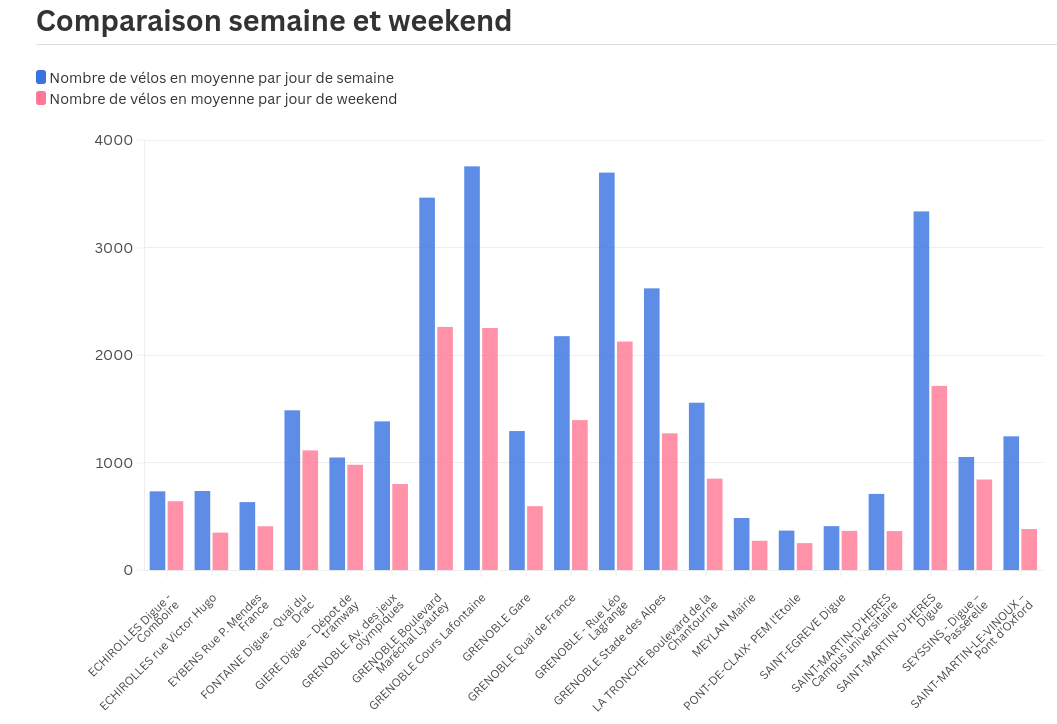

On donne ci-dessous le code qui permet de :

- filtrer les données de l'année 2022
- tracer le barplot corresondant au graphique désiré.

👉 Exécuter la cellule ci-dessous

In [ ]:
mask = bike['annee']==2022 #boolean mask for year 2022
df = bike[mask]
df.plot(x='nom_post',
        y=['tmjo', 'tmjwe'],
        kind='bar')

⬆️ Ce graphique correpsond à celui voulu, il va falloir désormais le personnaliser pour qu'il ressemble vraiment à l'objectif. Observez-les deux graphiques pour avoir une idée des éléments à modifier.

### Trier les données



Dans un premier temps, on observe que les valeurs sur l'ae des abcisses ne sont pas dans le même ordre. Il faudrait les trier par ordre alphabétique.

👉 Modifier la cellule ci-dessous pour afficher le graphiques avec les données triées par ordre alphabétique sur l'axe des abscisses.

💡 Indice : on utilisera `.sortvalues(...)` sur le DataFrame de départ.

In [ ]:
mask = bike['annee']==2022 #boolean mask for year 2022
df = bike[mask]
df.plot(x='nom_post',
        y=['tmjo', 'tmjwe'],
        kind='bar')

## Personnaliser la figure

👉 Reprendre le code précédent et ajouter une instruction pour changer la taille de la figure afin qu'elle ressemble à l'objectif.

In [ ]:
# YOUR CODE HERE

👉 Dans la cellule ci-dessous, repartir du code précédent et ajouter une ligne permettant d'insérer le titre 'Comparaison semaine et weekend'. Le titre doit être à gauche, et de taille 17.

In [ ]:
# YOUR CODE HERE

👉 Dans la cellule ci-dessous, repartir du code précédent et ajouter une ligne permettant de modifier la légende : 

- le texte doit être 'Nombre de vélos en moyenne par jour de semaine' et 'Nombre de vélos en moyenne par jour de weekend'
- la légende doit être en haut à gauche

In [ ]:
# YOUR CODE HERE

## Modifier les couleurs

👉 La cellule ci-dessous donne les codes couleurs du bleu et du rose utilisés dans le graphique souhaité. Complétez-là en reprenant le code utilisé jusqu'ici afin que le barplot ait les bonnes couleurs.


In [ ]:
# Colors
blue = '#5685D8'
pink = '#F0789A'

# YOUR CODE HERE

## Personnaliser la zone de tracé

👉 Continuer, en repartant du code précédent, à modifier le graphique pour : 

- ajouter une grille horizontale (avec `grid`)
- enlever le nom de l'axe des abscisses (`xlabel`)
- enlever le cadre autour du tracé (`spines`)
- enlever les ticks sur les axes (avec `plt.tickparams()`)

Enfin, ajouter cette commande pour incliner les étiquettes des abscisses de 45° :

```
plt.xticks(rotation=45, ha='right')
```


</details><details>
<summary>🎯 Objectif : le graphique doit ressembler à ceci</summary>

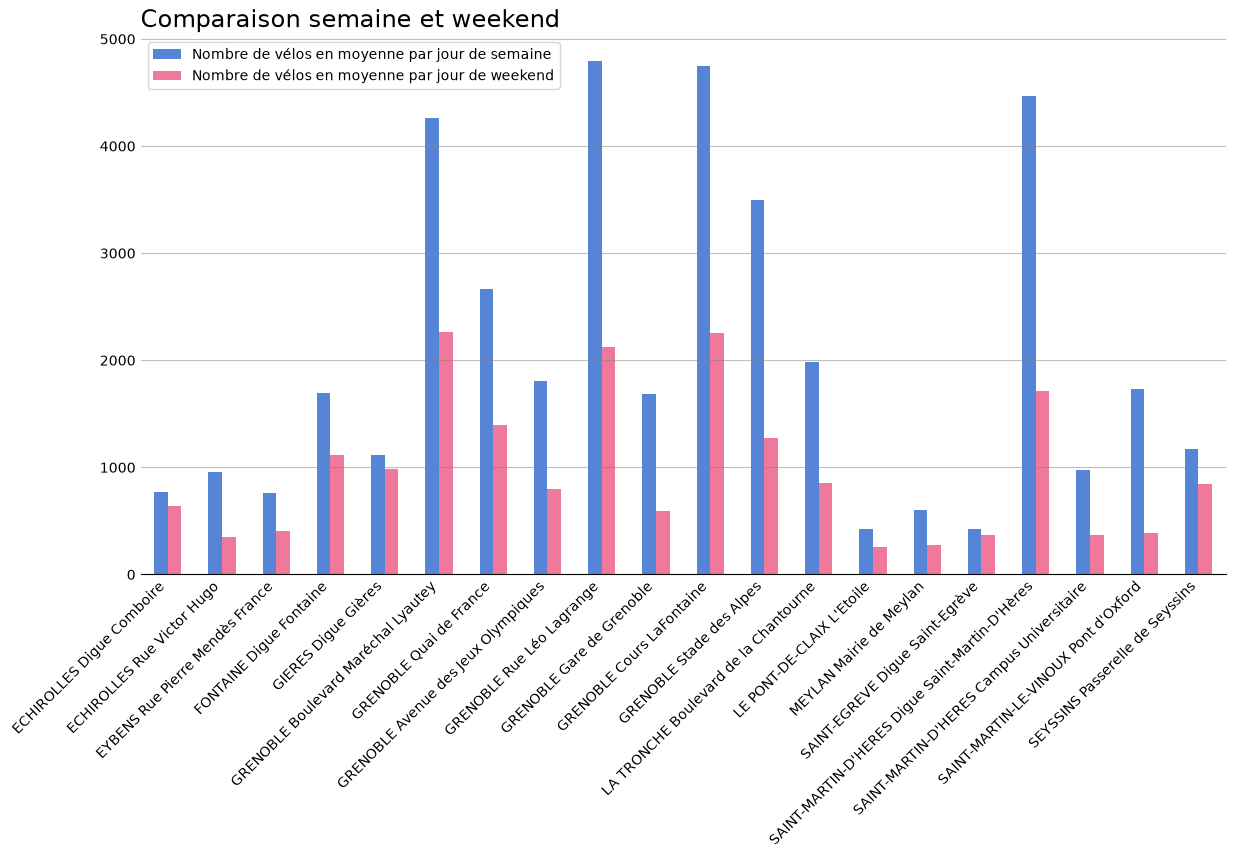
</details>

In [ ]:
# YOUR CODE HERE

## Exporter le graphique

👉 Pour sauvegarder la visualisation produite, reprenez votre code dans la cellule ci-dessous et ajoutez la ligne suivante : 

```
plt.savefig('mon_graphique.png', dpi=300)
```

Allez ensuite vérifier dans le dossier courant que l'image a bien été exportée.

In [ ]:
# YOUR CODE HERE

👉 Pour avoir une image en qualité HD, exportez plutôt le graphique produit au format PDF, bien meilleur que le PNG pour l'impression.

In [ ]:
# YOUR CODE HERE

## (optionnel) Trouver un juste milieu entre finetuning et temps passé à coder...

Un des objectifs pédagogiques de cet exercice est de montrer que personnaliser finement un graphique n'est pas chose aisée, et prend de nombreuses lignes de code...

Avant de se lancer dans une telle entreprise, il faut se demander si c'est vraiment utile : en général, un bon graphique est un graphique **simple**, et le coeur du travail réside en amont, dans la sélection, le filtrage, et le **choix des bonnes données à représenter**.

Dans l'exemple de et exercice, le graphique de départ était très bien, il aurait juste suffit de personnaliser : 

- le titre de la figure
- le titre des axes
- le contenu de la légende

La personnalisation fine d'un graphique est davantage le travail d'un.e graphiste, et croiser des compétences en graphisme et en python est un métier en soi : le data storytelling.

👉 En guise de preuve ultime que parfois le mieux est l'ennemi du bien, vous pouvez explorer le code ci-dessous, qui a pour but de reproduire les grapiques de la fin de [cette page](https://data.metropolegrenoble.fr/Tableau-de-bord-velo-grenoble?#fl-layout-wrapper-outer).

In [ ]:
# Nice plot

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from scipy.interpolate import make_interp_spline

# Filter and sort data
data = bike[bike['nom_post'] == "SAINT-MARTIN-D'HERES Digue Saint-Martin-D'Hères"]
data = data.sort_values('annee')

x = data['annee'].to_numpy()
y = data['tmj'].to_numpy()

# Smooth curve
x_smooth = np.linspace(x.min(), x.max(), 300)
y_smooth = make_interp_spline(x, y, k=3)(x_smooth)

# color codes
purple = '#4328e7'
grey = '#eeeeee'
dark_grey = '#4a4a4a'

# Smooth line and filled area
plt.figure(figsize=(5, 5))
plt.plot(x_smooth, y_smooth, color=purple, linewidth=2)
plt.fill_between(x_smooth, y_smooth, color=purple, alpha=0.75)

# Original data points
plt.scatter(x, y, color=purple, s=35, zorder=3)

# Value labels
for xi, yi in zip(x, y):
    plt.annotate(
        f'{int(yi)}',
        (xi, yi),
        xytext=(0, -15),
        textcoords='offset points',
        ha='center',
        color='white',
        fontsize=10,
        fontweight='bold',
        path_effects=[
            pe.withStroke(linewidth=2, foreground=purple)
        ]
    )
    
# Title
plt.title(
    "SAINT-MARTIN\nD'HERES Digue",
    color=purple,
    fontsize=12,
    fontweight='bold',
    loc='left'
)

# Axes
plt.ylim(bottom=0)
plt.xlabel('')
plt.ylabel('')
plt.xticks([2020, 2022], rotation=45)
plt.xlim((x.min(), x.max()+0.05))
plt.yticks([0, 1000, 2000, 3000, 4000])
plt.tick_params(
    axis='both',
    which='major',
    color=grey,  # Color of tick marks
    labelcolor=dark_grey  # Color of tick labels
)

# Grid and style
plt.grid(axis='y', color=grey, linewidth=1)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.gca().spines['left'].set_color(grey)
plt.gca().spines['bottom'].set_color(grey)

plt.tight_layout()
plt.show()

🏆 Cet exercice est terminé !